In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, DoubleType,
    StringType, TimestampType
)

In [2]:
from config import PROJECT_DIR, RAW_DIR, FIGURE_DIR, SPARK_LOCAL_THREADS, SPARK_SHUFFLE_PARTITIONS

# Local Spark: two worker threads and modest shuffle parallelism for 8 GB RAM.
# Change Java/Python environment outside the notebook if Spark cannot start.
spark = (
    SparkSession.builder
    .appName("ASHRAE_Data_Inspection")
    .master(f"local[{SPARK_LOCAL_THREADS}]")
    .config("spark.sql.shuffle.partitions", str(SPARK_SHUFFLE_PARTITIONS))
    .config("spark.sql.session.timeZone", "UTC")
    .getOrCreate()
)
print("Spark version:", spark.version)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark version: 4.3.0


In [3]:
print("Raw dataset directory:", RAW_DIR)
print("Directory exists:", RAW_DIR.exists())
print("Spark local test:")
spark.range(3).show()

Raw dataset directory: D:\Big Data Project\data\raw
Directory exists: True
Spark local test:
+---+
| id|
+---+
|  0|
|  1|
|  2|
+---+



## Verify dataset file sizes

In [4]:
files = sorted(RAW_DIR.glob("*.csv"))
file_info = [{"File": p.name, "Size (MiB)": round(p.stat().st_size / 1024**2, 2)}
             for p in files]
file_df = pd.DataFrame(file_info)
display(file_df)
print("Total size (GiB):", round(sum(p.stat().st_size for p in files) / 1024**3, 2))

,File,Size (MiB)
0,building_metadata.csv,0.04
1,sample_submission.csv,426.83
2,test.csv,1394.71
3,train.csv,647.18
4,weather_test.csv,14.10
5,weather_train.csv,7.10


Total size (GiB): 2.43


## Inspect the energy readings

In [5]:
train_path = RAW_DIR / "train.csv"
train_schema = StructType([
    StructField("building_id", IntegerType(), True),
    StructField("meter", IntegerType(), True),
    StructField("timestamp", TimestampType(), True),
    StructField("meter_reading", DoubleType(), True),
])
train = (
    spark.read
    .option("header", True)
    .schema(train_schema)
    .csv(train_path.as_posix())
)

train.show(10, truncate=False)
train.printSchema()
print("Columns:", train.columns)

+-----------+-----+-------------------+-------------+
|building_id|meter|timestamp          |meter_reading|
+-----------+-----+-------------------+-------------+
|0          |0    |2016-01-01 00:00:00|0.0          |
|1          |0    |2016-01-01 00:00:00|0.0          |
|2          |0    |2016-01-01 00:00:00|0.0          |
|3          |0    |2016-01-01 00:00:00|0.0          |
|4          |0    |2016-01-01 00:00:00|0.0          |
|5          |0    |2016-01-01 00:00:00|0.0          |
|6          |0    |2016-01-01 00:00:00|0.0          |
|7          |0    |2016-01-01 00:00:00|0.0          |
|8          |0    |2016-01-01 00:00:00|0.0          |
|9          |0    |2016-01-01 00:00:00|0.0          |
+-----------+-----+-------------------+-------------+
only showing top 10 rows
root
 |-- building_id: integer (nullable = true)
 |-- meter: integer (nullable = true)
 |-- timestamp: timestamp (nullable = true)
 |-- meter_reading: double (nullable = true)

Columns: ['building_id', 'meter', 'timesta

## Inspect building characteristics

In [6]:
building_path = RAW_DIR / "building_metadata.csv"
building_schema = StructType([
    StructField("site_id", IntegerType(), True),
    StructField("building_id", IntegerType(), True),
    StructField("primary_use", StringType(), True),
    StructField("square_feet", IntegerType(), True),
    StructField("year_built", DoubleType(), True),
    StructField("floor_count", DoubleType(), True),
])
buildings = spark.read.option("header", True).schema(building_schema).csv(building_path.as_posix())
print("Shape:", (buildings.count(), len(buildings.columns)))
buildings.show(10, truncate=False)
print("Missing values:")
missing_exprs = [F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
                 for c in buildings.columns]
buildings.agg(*missing_exprs).show(truncate=False)
print("Building categories:")
buildings.groupBy("primary_use").count().orderBy(F.desc("count")).show(30, truncate=False)

Shape: (1449, 6)
+-------+-----------+-------------------+-----------+----------+-----------+
|site_id|building_id|primary_use        |square_feet|year_built|floor_count|
+-------+-----------+-------------------+-----------+----------+-----------+
|0      |0          |Education          |7432       |2008.0    |NULL       |
|0      |1          |Education          |2720       |2004.0    |NULL       |
|0      |2          |Education          |5376       |1991.0    |NULL       |
|0      |3          |Education          |23685      |2002.0    |NULL       |
|0      |4          |Education          |116607     |1975.0    |NULL       |
|0      |5          |Education          |8000       |2000.0    |NULL       |
|0      |6          |Lodging/residential|27926      |1981.0    |NULL       |
|0      |7          |Education          |121074     |1989.0    |NULL       |
|0      |8          |Education          |60809      |2003.0    |NULL       |
|0      |9          |Office             |27000      |2010.0

## Inspect weather observations

In [7]:
weather_path = RAW_DIR / "weather_train.csv"
weather_schema = StructType([
    StructField("site_id", IntegerType(), True),
    StructField("timestamp", TimestampType(), True),
    StructField("air_temperature", DoubleType(), True),
    StructField("cloud_coverage", DoubleType(), True),
    StructField("dew_temperature", DoubleType(), True),
    StructField("precip_depth_1_hr", DoubleType(), True),
    StructField("sea_level_pressure", DoubleType(), True),
    StructField("wind_direction", DoubleType(), True),
    StructField("wind_speed", DoubleType(), True),
])
weather = spark.read.option("header", True).schema(weather_schema).csv(weather_path.as_posix())
weather.show(10, truncate=False)
weather.printSchema()
print("Columns:", weather.columns)

+-------+-------------------+---------------+--------------+---------------+-----------------+------------------+--------------+----------+
|site_id|timestamp          |air_temperature|cloud_coverage|dew_temperature|precip_depth_1_hr|sea_level_pressure|wind_direction|wind_speed|
+-------+-------------------+---------------+--------------+---------------+-----------------+------------------+--------------+----------+
|0      |2016-01-01 00:00:00|25.0           |6.0           |20.0           |NULL             |1019.7            |0.0           |0.0       |
|0      |2016-01-01 01:00:00|24.4           |NULL          |21.1           |-1.0             |1020.2            |70.0          |1.5       |
|0      |2016-01-01 02:00:00|22.8           |2.0           |21.1           |0.0              |1020.2            |0.0           |0.0       |
|0      |2016-01-01 03:00:00|21.1           |2.0           |20.6           |0.0              |1020.1            |0.0           |0.0       |
|0      |2016-01-01 

## Verify the dataset using PySpark aggregations

Spark aggregates the data in partitions; only small final summaries are converted to pandas.

In [8]:
# Keep the original energy records and metadata as Spark DataFrames.
# Filter once for electricity and reuse the logical expression below.
electricity = train.filter(F.col("meter") == 0)
# Building metadata is small enough for a broadcast join.
electricity_with_buildings = electricity.join(
    F.broadcast(buildings.select("building_id", "site_id", "primary_use", "square_feet")),
    on="building_id", how="inner"
)

In [9]:
meter_summary = (
    train.groupBy("meter")
    .agg(
        F.count("*").alias("total_records"),
        F.min("timestamp").alias("first_timestamp"),
        F.max("timestamp").alias("last_timestamp"),
        F.min("meter_reading").alias("minimum_reading"),
        F.max("meter_reading").alias("maximum_reading")
    ).orderBy("meter").toPandas()
)
display(meter_summary)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\types.py:786: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,meter,total_records,first_timestamp,last_timestamp,minimum_reading,maximum_reading
0,0,12060910,2016-01-01,2016-12-31 23:00:00,0.0,79769.0
1,1,4182440,2016-01-01,2016-12-31 23:00:00,0.0,880374.0
2,2,2708713,2016-01-01,2016-12-31 23:00:00,0.0,21904700.0
3,3,1264037,2016-01-01,2016-12-31 23:00:00,0.0,160187.0


In [10]:
meter_audit = (
    train.groupBy("meter")
    .agg(
        F.count("*").alias("total_records"),
        F.countDistinct("building_id").alias("unique_buildings"),
        F.sum(F.when(F.col("meter_reading") == 0, 1).otherwise(0)).alias("zero_readings"),
        (F.count("*") - F.count("meter_reading")).alias("missing_readings"),
        F.round(F.avg("meter_reading"), 2).alias("mean_reading"),
        # Spark's percentile_approx is approximate, unlike DuckDB's exact median.
        F.round(F.expr("percentile_approx(meter_reading, 0.5, 10000)"), 2).alias("median_reading")
    )
    .withColumn("zero_percentage", F.round(F.col("zero_readings") * 100 / F.col("total_records"), 2))
    .select("meter", "total_records", "unique_buildings", "zero_readings",
            "zero_percentage", "missing_readings", "mean_reading", "median_reading")
    .orderBy("meter")
    .toPandas()
)
display(meter_audit)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,meter,total_records,unique_buildings,zero_readings,zero_percentage,missing_readings,mean_reading,median_reading
0,0,12060910,1413,530169,4.40,0,170.83,62.80
1,1,4182440,498,656504,15.70,0,633.36,120.42
2,2,2708713,324,346960,12.81,0,13882.19,257.77
3,3,1264037,145,340343,26.93,0,385.87,39.59


In [11]:
site_audit = (
    electricity_with_buildings.groupBy("site_id")
    .agg(
        F.count("*").alias("electricity_records"),
        F.countDistinct("building_id").alias("buildings"),
        F.round(F.avg("meter_reading"), 2).alias("mean_reading")
    ).orderBy("site_id").toPandas()
)
display(site_audit)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,site_id,electricity_records,buildings,mean_reading
0,0,908409,105,226.53
1,1,447982,51,162.37
2,2,1184512,135,152.62
3,3,2370097,274,125.92
4,4,746746,91,181.09
5,5,781776,89,31.30
6,6,315436,36,176.28
7,7,104784,12,2041.81
8,8,567915,70,65.74
9,9,1068748,122,179.99


# Investigating electricity consumption

## Investigate the distribution of electricity readings

In [12]:
electricity_distribution = (
    electricity.agg(
        F.min("meter_reading").alias("minimum"),
        F.expr("percentile_approx(meter_reading, 0.25, 10000)").alias("q1"),
        F.expr("percentile_approx(meter_reading, 0.5, 10000)").alias("median"),
        F.expr("percentile_approx(meter_reading, 0.75, 10000)").alias("q3"),
        F.expr("percentile_approx(meter_reading, 0.95, 10000)").alias("p95"),
        F.expr("percentile_approx(meter_reading, 0.99, 10000)").alias("p99"),
        F.max("meter_reading").alias("maximum")
    ).toPandas()
)
display(electricity_distribution)
print("Note: Spark percentile_approx gives approximate quantiles; small differences are expected.")

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,minimum,q1,median,q3,p95,p99,maximum
0,0.0,19.5,62.825,170.04,647.19,1628.17,79769.0


Note: Spark percentile_approx gives approximate quantiles; small differences are expected.


## Examine zero readings by site

In [13]:
zero_by_site = (
    electricity_with_buildings.groupBy("site_id")
    .agg(
        F.count("*").alias("total_records"),
        F.sum(F.when(F.col("meter_reading") == 0, 1).otherwise(0)).alias("zero_readings")
    )
    .withColumn("zero_percentage", F.round(F.col("zero_readings") * 100 / F.col("total_records"), 2))
    .orderBy(F.desc("zero_percentage"))
    .toPandas()
)
display(zero_by_site)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,site_id,total_records,zero_readings,zero_percentage
0,0,908409,346426,38.14
1,7,104784,12632,12.06
2,8,567915,26582,4.68
3,14,890768,40538,4.55
4,9,1068748,44786,4.19
5,13,1236660,19874,1.61
6,15,841195,12428,1.48
7,5,781776,8023,1.03
8,2,1184512,9944,0.84
9,4,746746,3879,0.52


## Identify buildings with the highest average consumption

In [14]:
top_buildings = (
    electricity_with_buildings
    .groupBy("building_id", "site_id", "primary_use", "square_feet")
    .agg(
        F.count("*").alias("observations"),
        F.round(F.avg("meter_reading"), 2).alias("mean_reading"),
        F.round(F.max("meter_reading"), 2).alias("max_reading")
    )
    .orderBy(F.desc("mean_reading"))
    .limit(15).toPandas()
)
display(top_buildings)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,building_id,site_id,primary_use,square_feet,observations,mean_reading,max_reading
0,801,7,Education,484376,8781,4650.17,7296.45
1,794,7,Education,731945,8782,4125.03,6013.39
2,803,7,Education,182986,8189,3613.62,5914.19
3,1088,13,Education,287594,8769,3430.59,8894.00
4,797,7,Education,764237,8781,3106.07,5246.31
5,223,2,Education,261188,8782,2496.68,3193.57
6,795,7,Education,387500,8780,2429.26,5399.10
7,375,3,Office,850354,8782,2048.10,3095.44
8,1168,13,Office,577101,8528,1963.89,44336.50
9,799,7,Education,527431,8781,1945.10,17502.10


## Generate our first distribution visualization

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


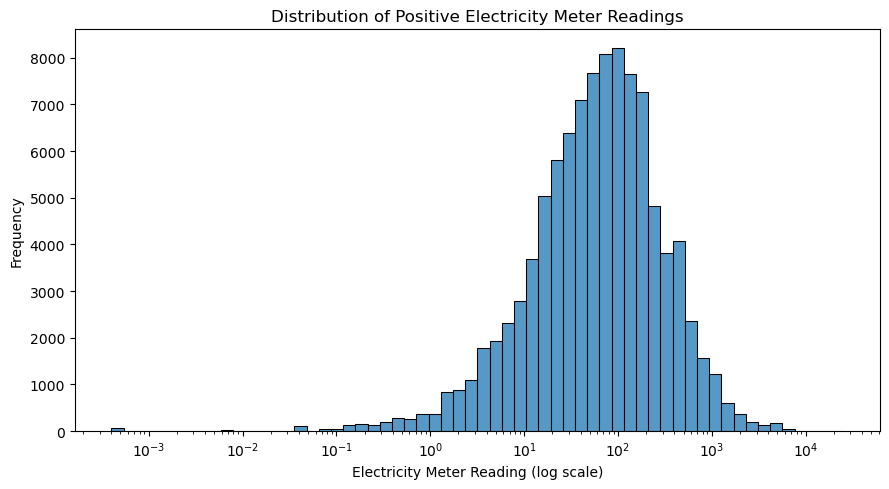

In [15]:
# Collect only a small reproducible sample for visualization, not the full CSV.
sample_df = (
    electricity.filter(F.col("meter_reading") > 0)
    .sample(withReplacement=False, fraction=0.02, seed=42)
    .select("meter_reading")
    .limit(100_000)
    .toPandas()
)

plt.figure(figsize=(9, 5))
sns.histplot(data=sample_df, x="meter_reading", bins=60, log_scale=(True, False))
plt.title("Distribution of Positive Electricity Meter Readings")
plt.xlabel("Electricity Meter Reading (log scale)")
plt.ylabel("Frequency")
plt.tight_layout()
# plt.savefig(FIGURE_DIR / "distribution_positive_electricity_meter_readings.png", bbox_inches="tight")
plt.show()

# Investigate Site 0 and zero-reading patterns

## Which buildings contribute most to Site 0's zero readings?

In [16]:
site0_buildings = (
    electricity_with_buildings.filter(F.col("site_id") == 0)
    .groupBy("building_id", "primary_use", "square_feet")
    .agg(
        F.count("*").alias("total_records"),
        F.sum(F.when(F.col("meter_reading") == 0, 1).otherwise(0)).alias("zero_readings"),
        F.round(F.avg("meter_reading"), 2).alias("mean_reading")
    )
    .withColumn("zero_percentage", F.round(F.col("zero_readings") * 100 / F.col("total_records"), 2))
    .select("building_id", "primary_use", "square_feet", "total_records",
            "zero_readings", "zero_percentage", "mean_reading")
    .orderBy(F.desc("zero_readings"))
    .limit(20).toPandas()
)
display(site0_buildings)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,building_id,primary_use,square_feet,total_records,zero_readings,zero_percentage,mean_reading
0,45,Retail,15304,8783,4356,49.60,1.65
1,69,Parking,387638,8784,3627,41.29,61.45
2,71,Parking,387638,8784,3389,38.58,86.55
3,59,Entertainment/public assembly,81337,8784,3383,38.51,107.72
4,86,Education,10932,8784,3380,38.48,53.54
5,82,Office,10743,8784,3379,38.47,33.18
6,90,Lodging/residential,59200,8784,3378,38.46,210.72
7,102,Office,15876,8784,3378,38.46,80.14
8,99,Office,2260,8784,3378,38.46,11.02
9,15,Office,83957,8784,3378,38.46,164.88


## Are zero readings concentrated in particular months?

In [17]:
site0_monthly = (
    electricity_with_buildings.filter(F.col("site_id") == 0)
    .withColumn("month", F.date_format("timestamp", "yyyy-MM"))
    .groupBy("month")
    .agg(
        F.count("*").alias("total_records"),
        F.sum(F.when(F.col("meter_reading") == 0, 1).otherwise(0)).alias("zero_readings")
    )
    .withColumn("zero_percentage", F.round(F.col("zero_readings") * 100 / F.col("total_records"), 2))
    .orderBy("month").toPandas()
)
display(site0_monthly)

C:\Users\Fahad\anaconda3\Lib\site-packages\pyspark\sql\pandas\conversion.py:324: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,month,total_records,zero_readings,zero_percentage
0,2016-01,76431,75224,98.42
1,2016-02,71567,70467,98.46
2,2016-03,76745,76347,99.48
3,2016-04,74373,74024,99.53
4,2016-05,76430,48850,63.91
5,2016-06,74303,952,1.28
6,2016-07,76719,131,0.17
7,2016-08,77182,60,0.08
8,2016-09,74880,28,0.04
9,2016-10,77374,57,0.07


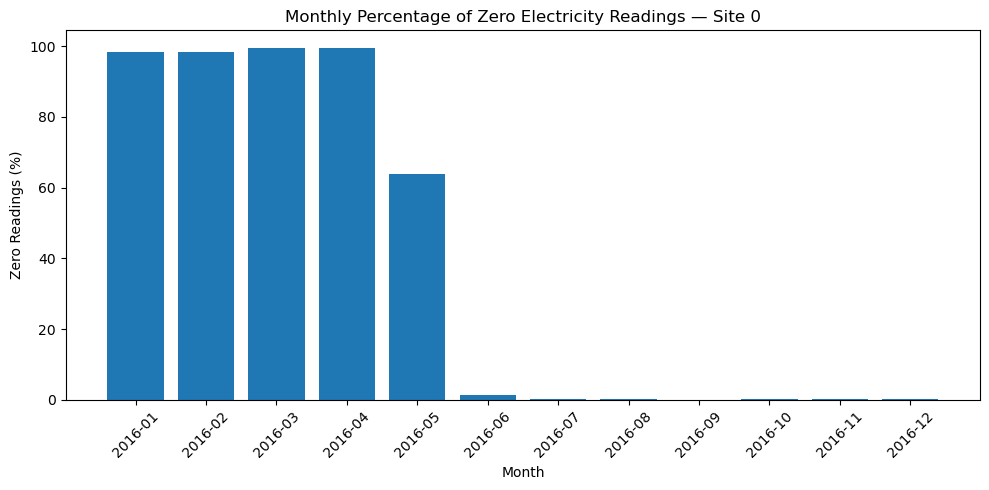

In [18]:
plt.figure(figsize=(10, 5))

plt.bar(
    site0_monthly["month"],
    site0_monthly["zero_percentage"]
)

plt.title("Monthly Percentage of Zero Electricity Readings — Site 0")
plt.xlabel("Month")
plt.ylabel("Zero Readings (%)")
plt.xticks(rotation=45)

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "monthly_percentage_of_zero_electricity_readings_site0.png", bbox_inches="tight")
plt.show()

### Reproducibility note

The full dataset is inspected using PySpark locally. Only small aggregated results and a capped plotting sample are converted to pandas. `percentile_approx` may differ slightly from DuckDB's exact quantiles. After using Spark, run `spark.stop()` when finished with this notebook.

In [20]:
spark.stop()